# Install Dependencies

In [1]:
%pip install numpy pandas scikit-learn matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


# Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import seaborn as sns

%matplotlib inline

# Load Data

In [56]:
df = pd.read_csv('Salary_Data.csv')
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 6704 entries, 0 to 6703
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  6702 non-null   float64
 1   Gender               6702 non-null   str    
 2   Education Level      6701 non-null   str    
 3   Job Title            6702 non-null   str    
 4   Years of Experience  6701 non-null   float64
 5   Salary               6699 non-null   float64
dtypes: float64(3), str(3)
memory usage: 314.4 KB


,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


# Exploratory Data Analysis

In [8]:
print(f"Dataset Shape: {df.shape}")
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape: (6704, 6)
Number of Rows: 6704
Number of Columns: 6


In [9]:
display(df.head(10))
display(df.tail(10))

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0
5,29.0,Male,Bachelor's,Marketing Analyst,2.0,55000.0
6,42.0,Female,Master's,Product Manager,12.0,120000.0
7,31.0,Male,Bachelor's,Sales Manager,4.0,80000.0
8,26.0,Female,Bachelor's,Marketing Coordinator,1.0,45000.0
9,38.0,Male,PhD,Senior Scientist,10.0,110000.0


,Age,Gender,Education Level,Job Title,Years of Experience,Salary
6694,27.0,Male,High School,Digital Marketing Manager,2.0,40000.0
6695,33.0,Female,Bachelor's Degree,Content Marketing Manager,7.0,90000.0
6696,28.0,Male,PhD,Sales Representative,4.0,55000.0
6697,51.0,Female,Master's Degree,Senior Product Marketing Manager,19.0,190000.0
6698,37.0,Male,Bachelor's Degree,Junior Sales Representative,6.0,75000.0
6699,49.0,Female,PhD,Director of Marketing,20.0,200000.0
6700,32.0,Male,High School,Sales Associate,3.0,50000.0
6701,30.0,Female,Bachelor's Degree,Financial Manager,4.0,55000.0
6702,46.0,Male,Master's Degree,Marketing Manager,14.0,140000.0
6703,26.0,Female,High School,Sales Executive,1.0,35000.0


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6704 entries, 0 to 6703
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  6702 non-null   float64
 1   Gender               6702 non-null   str    
 2   Education Level      6701 non-null   str    
 3   Job Title            6702 non-null   str    
 4   Years of Experience  6701 non-null   float64
 5   Salary               6699 non-null   float64
dtypes: float64(3), str(3)
memory usage: 314.4 KB


dataset has null values

In [13]:
display(df.describe())

,Age,Years of Experience,Salary
count,6702.000000,6701.000000,6699.000000
mean,33.620859,8.094687,115326.964771
std,7.614633,6.059003,52786.183911
min,21.000000,0.000000,350.000000
25%,28.000000,3.000000,70000.000000
50%,32.000000,7.000000,115000.000000
75%,38.000000,12.000000,160000.000000
max,62.000000,34.000000,250000.000000


## Missing Values

In [14]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

display(missing)

,Missing Count,Missing Percentage
Age,2,0.029833
Gender,2,0.029833
Education Level,3,0.044749
Job Title,2,0.029833
Years of Experience,3,0.044749
Salary,5,0.074582


Empty salary rows is unexpected

## Duplicate Rows

In [15]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 4912


There is too many duplicate rows in the dataset

## Unique Values

In [19]:
for column in df.columns:
    print(f"\n{column}")
    print("Unique Values:", df[column].nunique())
    print(df[column].unique()[:10])


Age
Unique Values: 41
[32. 28. 45. 36. 52. 29. 42. 31. 26. 38.]

Gender
Unique Values: 3
<StringArray>
['Male', 'Female', nan, 'Other']
Length: 4, dtype: str

Education Level
Unique Values: 7
<StringArray>
[       'Bachelor's',          'Master's',               'PhD',
                 nan, 'Bachelor's Degree',   'Master's Degree',
       'High School',               'phD']
Length: 8, dtype: str

Job Title
Unique Values: 193
<StringArray>
[    'Software Engineer',          'Data Analyst',        'Senior Manager',
       'Sales Associate',              'Director',     'Marketing Analyst',
       'Product Manager',         'Sales Manager', 'Marketing Coordinator',
      'Senior Scientist']
Length: 10, dtype: str

Years of Experience
Unique Values: 37
[ 5.  3. 15.  7. 20.  2. 12.  4.  1. 10.]

Salary
Unique Values: 444
[ 90000.  65000. 150000.  60000. 200000.  55000. 120000.  80000.  45000.
 110000.]


in dataset has non values

## Numerical distributions

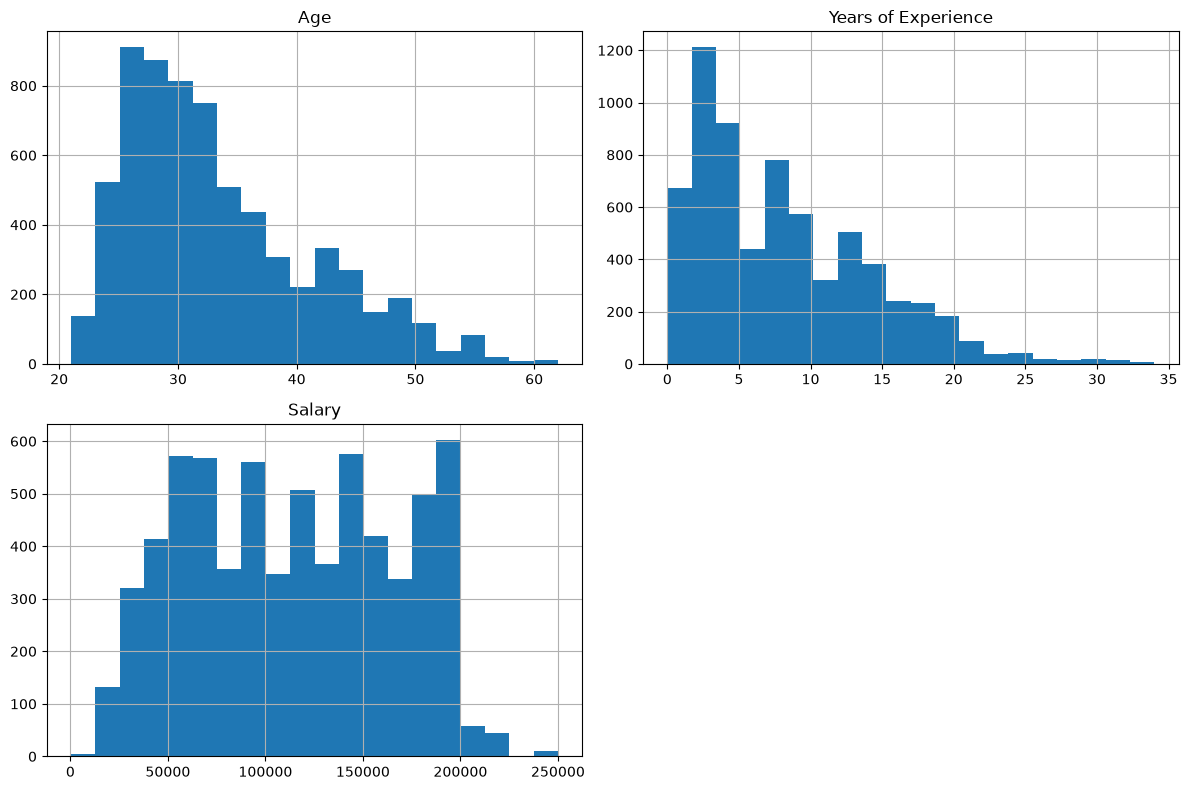

In [20]:
df.hist(figsize=(12, 8), bins=20)
plt.tight_layout()
plt.show()

Age 22-34 </br>
Experience 0-5 </br>
Salary uneven distribution </br>


## Outliers

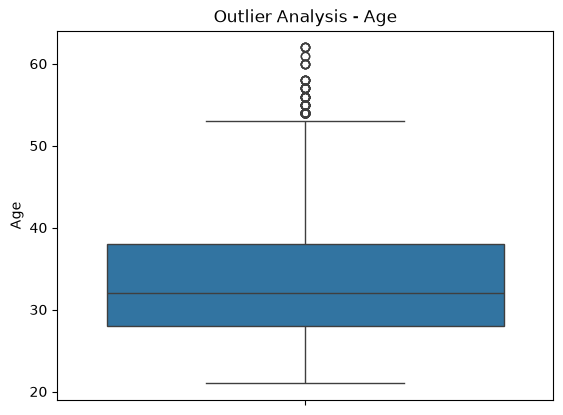

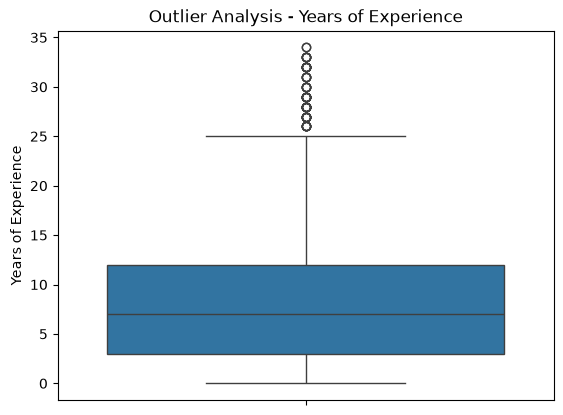

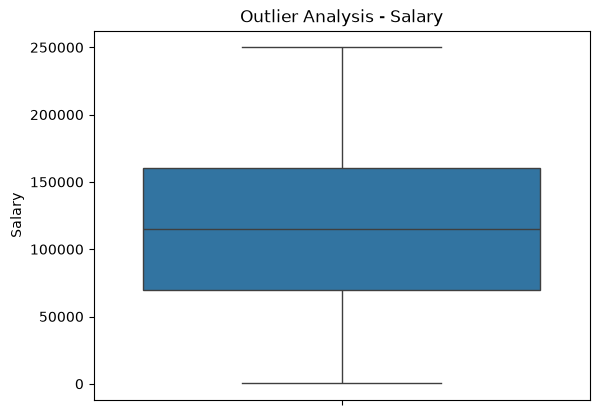

In [32]:
for column in df.select_dtypes(include=np.number).columns:
    sns.boxplot(data=df[column])
    plt.xticks(rotation=45)
    plt.title(f"Outlier Analysis - {column}")
    plt.show()



## Korrelation Matrix

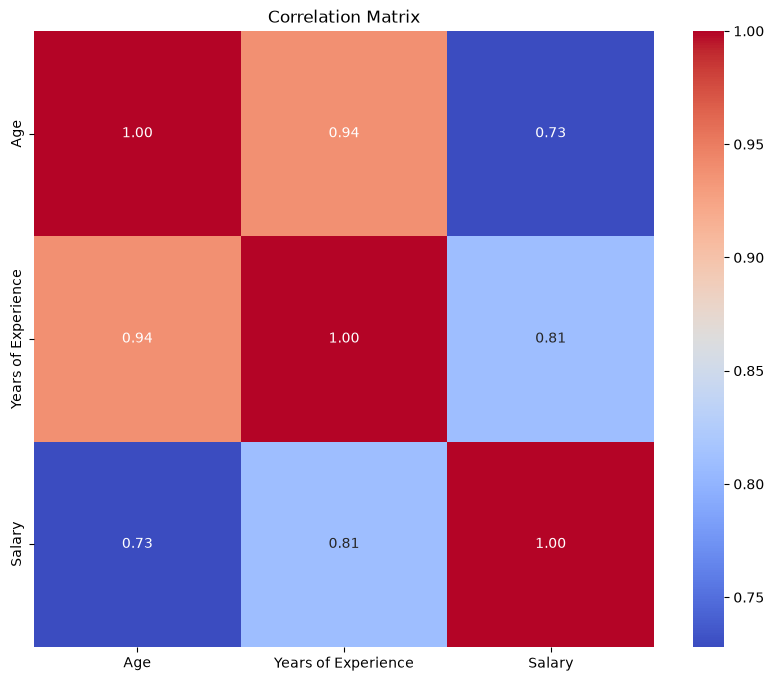

In [36]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

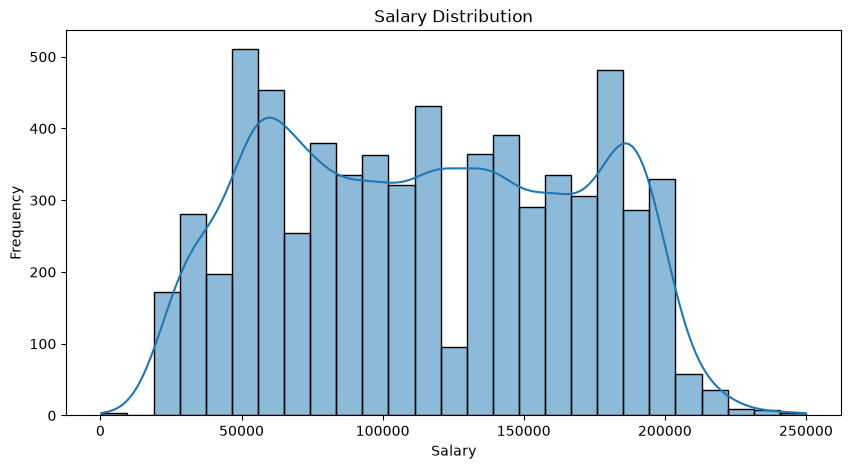

In [37]:
plt.figure(figsize=(10, 5))

sns.histplot(df["Salary"], kde=True)

plt.title("Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Frequency")

plt.show()

# Data Cleaning

In [41]:
print(df.dtypes)
df.info()

Age                    float64
Gender                     str
Education Level            str
Job Title                  str
Years of Experience    float64
Salary                 float64
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 6704 entries, 0 to 6703
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  6702 non-null   float64
 1   Gender               6702 non-null   str    
 2   Education Level      6701 non-null   str    
 3   Job Title            6702 non-null   str    
 4   Years of Experience  6701 non-null   float64
 5   Salary               6699 non-null   float64
dtypes: float64(3), str(3)
memory usage: 314.4 KB


## Renaming Column Names

In [78]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(df.columns.tolist())

['age', 'gender', 'education_level', 'job_title', 'years_of_experience', 'salary']


## Duplicate Values

In [ ]:
duplicate_count = df.duplicated().sum()

print("Duplicate Rows:", duplicate_count)

display(df[df.duplicated(keep=False)].sort_values(by=df.columns.tolist()))

Duplicate Rows: 4912


,age,gender,education_level,job_title,years_of_experience,salary
4884,21.0,Female,High School,Junior Sales Representative,0.0,25000.0
4897,21.0,Female,High School,Junior Sales Representative,0.0,25000.0
4910,21.0,Female,High School,Junior Sales Representative,0.0,25000.0
4923,21.0,Female,High School,Junior Sales Representative,0.0,25000.0
4936,21.0,Female,High School,Junior Sales Representative,0.0,25000.0
...,...,...,...,...,...,...
1305,62.0,Male,PhD,Software Engineer Manager,19.0,200000.0
1236,62.0,Male,PhD,Software Engineer Manager,20.0,200000.0
1304,62.0,Male,PhD,Software Engineer Manager,20.0,200000.0
172,NaN,NaN,NaN,NaN,NaN,NaN


Duplicate rows should not be removed from the dataset. <br>
There may be more than one person of the same age, profession and experience

## Missing Values

In [ ]:
missing_analysis = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing_analysis)

,Missing_Count,Missing_Percentage
age,2,0.03
gender,2,0.03
education_level,3,0.04
job_title,2,0.03
years_of_experience,3,0.04
salary,5,0.07


In [ ]:
for line in df.iterrows():
    if line[1].isnull().values.any():
        print(f"Row {line[0]} has missing values: {line[1].isnull().values.sum()}")

Row 2011 has missing values: [False False  True False False False]


### Cleaning Empty Rows

In [57]:
missing_per_row = df.isna().sum(axis=1)
rows_to_drop = missing_per_row[missing_per_row > 5].index

print(f"Rows to drop: {len(rows_to_drop)}")

Rows to drop: 2


In [58]:
df = df.drop(rows_to_drop)
print(f"New Dataset Shape: {df.shape}")

New Dataset Shape: (6702, 6)


6704 -> 6702

### Remove Rows dont have Salary information

In [79]:
df.dropna(subset=['salary'], inplace=True)
print(f"New Dataset Shape: {df.shape}")

New Dataset Shape: (6699, 6)


/var/folders/5q/c8vqlbs52kg0glc8tpd0p0600000gn/T/ipykernel_68980/2935326605.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(subset=['salary'], inplace=True)


6702 -> 6699

### Replace Missing Values with Most Frequent Value

In [72]:
column_names = df.columns.tolist()

for line in df.iterrows():
    if line[1].isnull().values.any():
        columns_with_missing = [column_names[i] for i, is_null in enumerate(line[1].isnull().values) if is_null]
        print(f"Row {line[0]} has missing values in columns: {columns_with_missing}")


Row 2011 has missing values in columns: ['Education Level']


In [84]:
mfv_education_level = df.mode().iloc[0]['education_level']
print(mfv_education_level)

df.fillna({'education_level': mfv_education_level}, inplace=True)
df.info()

Bachelor's Degree
<class 'pandas.DataFrame'>
Index: 6699 entries, 0 to 6703
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  6699 non-null   float64
 1   gender               6699 non-null   str    
 2   education_level      6699 non-null   str    
 3   job_title            6699 non-null   str    
 4   years_of_experience  6699 non-null   float64
 5   salary               6699 non-null   float64
dtypes: float64(3), str(3)
memory usage: 366.4 KB
